# Datathon Task 1 V3 — Regime-Aware Global Context

Notebook ini adalah eksperimen end-to-end untuk forecasting speed 1.260 ruas pada +20, +40, dan +60 menit. Alurnya sengaja urut: audit data → EDA → validasi → baseline → reverse engineering regime → preprocessing text → ablation neural → evaluasi → ensemble → full refit → submission.

**Target V3:** mencari signal baru di luar V2, bukan sekadar menambah epoch. V2 sudah mencapai local MSE 27.4269, tetapi prediksinya berkorelasi >0.998 dengan V1. Diagnosis manual menemukan test merupakan campuran m1-like/m2-like sekitar 69%/31%. Karena hard expert per regime justru lebih buruk, regime dipakai sebagai *soft context* untuk memodulasi representasi semua road.

> Runtime yang direkomendasikan: Kaggle **GPU T4**, internet off. Notebook memakai FP32 dan `num_workers=0`, konfigurasi yang sudah terbukti stabil. Semua output disimpan ke `/kaggle/working`.


## 1. Hipotesis, guardrail, dan success criteria

Hipotesis yang diuji:

1. **V2 reference** memastikan perubahan protocol tidak diam-diam merusak model.
2. **Global FiLM** memberi model ringkasan keadaan kota (mean, std, zero-rate per lag) dan probabilitas regime untuk mengubah skala/bias fitur road.
3. **EMA** merata-ratakan bobot sepanjang training agar validation lebih stabil.
4. **Soft mixture-of-experts** memberi dua residual head dan mencampurnya secara probabilistik. Ini lebih aman daripada hard split yang sudah gagal pada eksperimen AR.

Success criterion utama adalah test-composition-weighted validation MSE. Balanced 50/50 MSE tetap ditampilkan agar comparable dengan V1/V2. Tidak ada leaderboard claim sebelum submission sungguhan.


In [13]:
from __future__ import annotations

import copy, gc, importlib, json, os, random, time
from dataclasses import dataclass, asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm, trange

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

BASE_SEED=42; V1_REFERENCE_MSE=27.8935; V2_REFERENCE_MSE=27.426926
HORIZONS=(5,10,15); N_ROADS=1260; HISTORY=15
KAGGLE_INPUT=Path('/kaggle/input/competitions/datathon-task-1/dataset-task1')
LOCAL_CANDIDATES=[Path.cwd()/'dataset-task1']+[p/'dataset-task1' for p in Path.cwd().parents]
LOCAL_INPUT=next((p for p in LOCAL_CANDIDATES if p.exists()),LOCAL_CANDIDATES[0])
DATA_DIR=KAGGLE_INPUT if KAGGLE_INPUT.exists() else LOCAL_INPUT
IS_KAGGLE=KAGGLE_INPUT.exists(); FAST_MODE=os.getenv('DATATON_FAST_MODE','0')=='1'
OUTPUT_DIR=Path('/kaggle/working') if IS_KAGGLE else DATA_DIR.parent/'tmp/jupyter-notebook/v3-smoke'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

VAL_STEPS=720 if not FAST_MODE else 120
EXPERIMENT_STRIDE=2 if not FAST_MODE else 40
FINAL_STRIDE=1 if not FAST_MODE else 40
PCA_DIM=48 if not FAST_MODE else 8; TEXT_DIM=32 if not FAST_MODE else 8
HIDDEN_DIM=64 if not FAST_MODE else 16
EXPERIMENT_EPOCHS=12 if not FAST_MODE else 1
SEED_SEARCH_EPOCHS=16 if not FAST_MODE else 1
PATIENCE=4; SEEDS=[42,2026,3407] if not FAST_MODE else [42]
BATCH_SIZE=16 if torch.cuda.is_available() else (4 if not FAST_MODE else 2)
NUM_WORKERS=0
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))

if not hasattr(torch,'_utils'): torch._utils=importlib.import_module('torch._utils')
probe=nn.Parameter(torch.tensor([1.])); opt=torch.optim.AdamW([probe],lr=1e-3)
(probe**2).sum().backward(); opt.step(); del probe,opt

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(BASE_SEED)
print('Optimizer preflight OK | torch',torch.__version__)
print({'data':str(DATA_DIR),'output':str(OUTPUT_DIR),'device':str(DEVICE),'fast_mode':FAST_MODE,
       'experiment_stride':EXPERIMENT_STRIDE,'final_stride':FINAL_STRIDE,'num_workers':NUM_WORKERS})
assert DATA_DIR.exists(),f'Dataset tidak ditemukan: {DATA_DIR}'


Optimizer preflight OK | torch 2.10.0+cu128
{'data': '/kaggle/input/competitions/datathon-task-1/dataset-task1', 'output': '/kaggle/working', 'device': 'cuda', 'fast_mode': False, 'experiment_stride': 2, 'final_stride': 1, 'num_workers': 0}


## 2. Load data dan EDA

EDA tidak hanya dekoratif. Kita memeriksa tiga hal yang langsung menentukan preprocessing/model: distribution shift m1–m2, prevalensi nol, serta sparsity/direction graph. Tabel selalu dicetak bersama plot agar hasil tetap machine-readable.


,split,shape,mean,std,zero_%,min,max
0,train_speed_m1_1_11160,"(11160, 1260)",54.992,17.048,1.036,0.0,142.0
1,train_speed_m2_1_5039,"(5039, 1260)",49.184,26.218,16.672,0.0,151.0
2,test_history,"(540, 15, 1260)",52.729,20.416,5.937,0.0,137.0


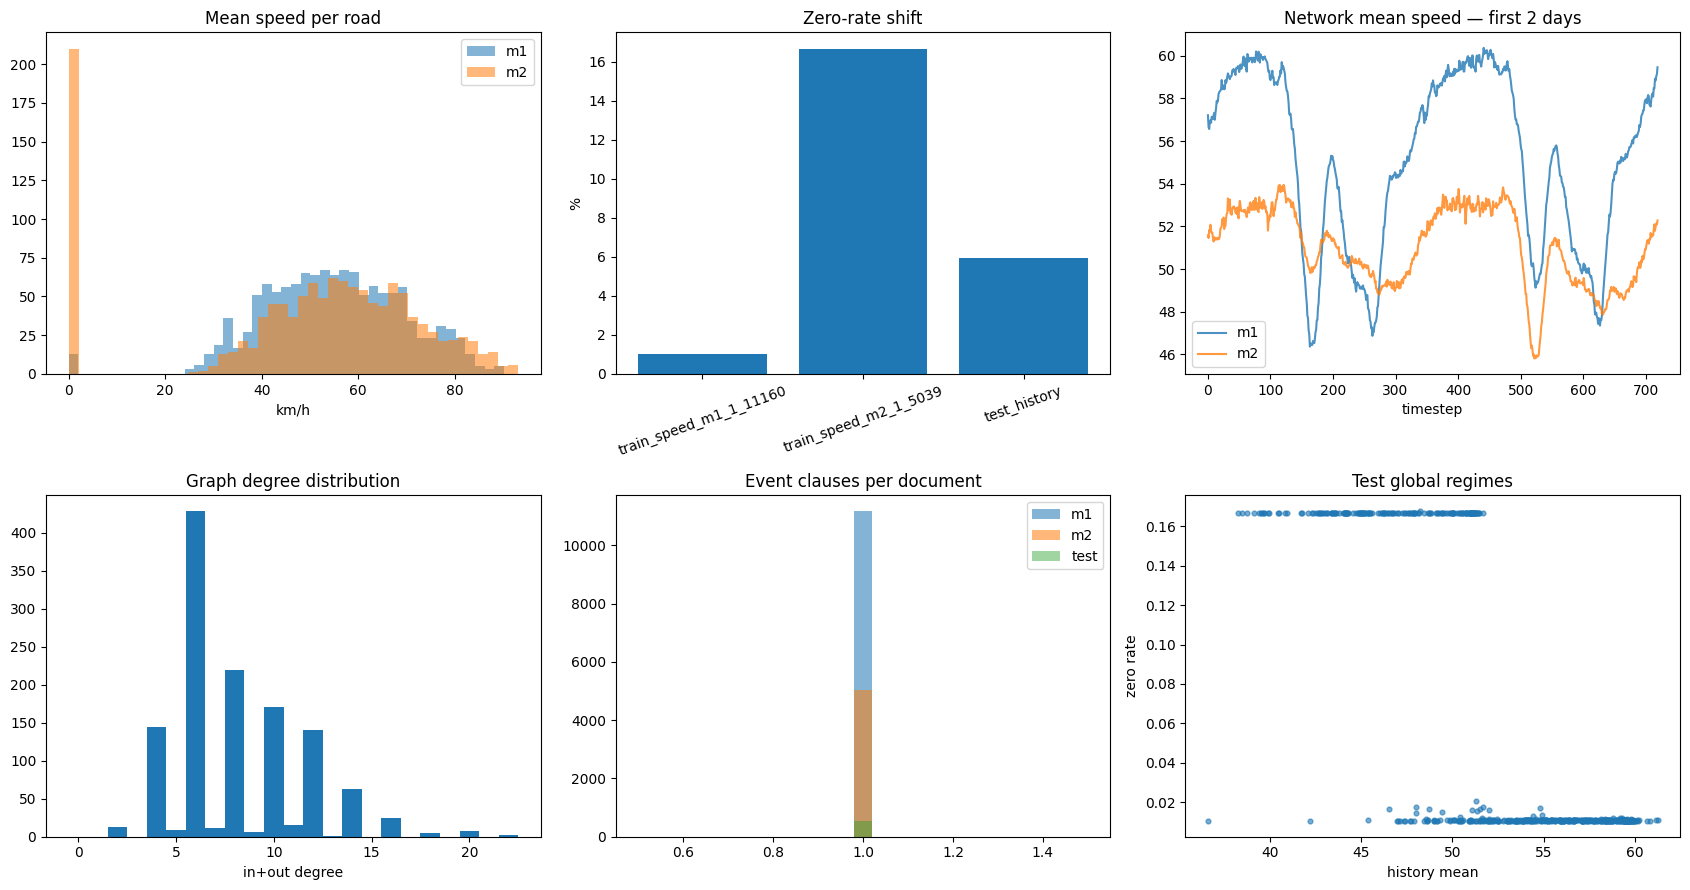

Graph nonzero incl diagonal: 5122 | degree min/median/max: 2 8.0 22
Text clauses median m1/m2/test: 1.0 1.0 1.0


In [14]:
def load_json_values(path):
    with Path(path).open() as f: return list(json.load(f).values())

speed_paths=sorted((DATA_DIR/'train').glob('train_speed_*.npy'))
text_paths=sorted((DATA_DIR/'train').glob('train_text_*.json'))
train_speeds=[np.load(p,mmap_mode='r') for p in speed_paths]
train_texts=[load_json_values(p) for p in text_paths]
test_hist=np.load(DATA_DIR/'test/test_X_hist.npy')
test_texts=load_json_values(DATA_DIR/'test/test_texts.json')
adjacency=np.load(DATA_DIR/'static/matrix.npy')
sample_submission=pd.read_csv(DATA_DIR/'sample_submission.csv')
assert [z.shape[1] for z in train_speeds]==[N_ROADS,N_ROADS]
assert test_hist.shape[1:]==(HISTORY,N_ROADS) and adjacency.shape==(N_ROADS,N_ROADS)

summary=pd.DataFrame([
    {'split':p.stem,'shape':str(z.shape),'mean':float(z.mean()),'std':float(z.std()),
     'zero_%':100*float(np.mean(z==0)),'min':float(z.min()),'max':float(z.max())}
    for p,z in zip(speed_paths,train_speeds)
]+[{'split':'test_history','shape':str(test_hist.shape),'mean':float(test_hist.mean()),
    'std':float(test_hist.std()),'zero_%':100*float(np.mean(test_hist==0)),
    'min':float(test_hist.min()),'max':float(test_hist.max())}])
display(summary.round(3))

src_all,dst_all=np.nonzero(adjacency!=0)
degree=np.bincount(np.r_[src_all,dst_all],minlength=N_ROADS)
doc_lengths=[[len(x.split(' | ')) for x in block] for block in train_texts]
test_doc_lengths=[len(x.split(' | ')) for x in test_texts]

fig,ax=plt.subplots(2,3,figsize=(17,9))
for z,label in zip(train_speeds,['m1','m2']): ax[0,0].hist(np.asarray(z).mean(0),bins=45,alpha=.55,label=label)
ax[0,0].set(title='Mean speed per road',xlabel='km/h'); ax[0,0].legend()
ax[0,1].bar(summary['split'],summary['zero_%']); ax[0,1].set(title='Zero-rate shift',ylabel='%'); ax[0,1].tick_params(axis='x',rotation=20)
for z,label in zip(train_speeds,['m1','m2']): ax[0,2].plot(np.asarray(z[:720]).mean(1),label=label,alpha=.8)
ax[0,2].set(title='Network mean speed — first 2 days',xlabel='timestep'); ax[0,2].legend()
ax[1,0].hist(degree,bins=np.arange(degree.max()+2)-.5); ax[1,0].set(title='Graph degree distribution',xlabel='in+out degree')
ax[1,1].hist(doc_lengths[0],bins=25,alpha=.55,label='m1'); ax[1,1].hist(doc_lengths[1],bins=25,alpha=.55,label='m2'); ax[1,1].hist(test_doc_lengths,bins=25,alpha=.45,label='test')
ax[1,1].set(title='Event clauses per document'); ax[1,1].legend()
test_global_mean=test_hist.mean((1,2)); test_zero=(test_hist==0).mean((1,2))
ax[1,2].scatter(test_global_mean,test_zero,s=12,alpha=.6); ax[1,2].set(title='Test global regimes',xlabel='history mean',ylabel='zero rate')
plt.tight_layout(); plt.show()
print('Graph nonzero incl diagonal:',int(np.count_nonzero(adjacency)),'| degree min/median/max:',int(degree.min()),float(np.median(degree)),int(degree.max()))
print('Text clauses median m1/m2/test:',np.median(doc_lengths[0]),np.median(doc_lengths[1]),np.median(test_doc_lengths))


### EDA interpretation

- m2 memiliki zero-rate jauh lebih tinggi daripada m1; nol dipertahankan dan diberikan sebagai mask, bukan diimputasi buta.
- Graph sparse dan directed; incoming/outgoing aggregation dipisahkan.
- Test terlihat sebagai dua cluster global. Kita ukur ini secara eksplisit di bagian regime.
- Recent-history smoothing tetap menjadi base forecast karena linear trend sebelumnya mudah meledak pada metric MSE.


## 3. Leakage-safe temporal validation

Random split dilarang karena window overlap. V3 juga memperbaiki detail kecil V2: waktu train berhenti sebelum seluruh future horizon melewati cut, sehingga tidak ada target train yang masuk ke periode validation. Dua score dilaporkan:

- `balanced`: dua block validation punya bobot 50/50, comparable dengan laporan lama;
- `test_weighted`: bobot mengikuti komposisi regime yang diinferensikan dari test.


In [15]:
def valid_times(n,start,stop,stride=1):
    return np.arange(max(HISTORY-1,start),min(stop,n-max(HORIZONS)),stride,dtype=np.int32)

cuts=[len(z)-VAL_STEPS for z in train_speeds]
experiment_times=[valid_times(len(z),HISTORY-1,cut-max(HORIZONS)+1,EXPERIMENT_STRIDE) for z,cut in zip(train_speeds,cuts)]
final_train_times=[valid_times(len(z),HISTORY-1,cut-max(HORIZONS)+1,FINAL_STRIDE) for z,cut in zip(train_speeds,cuts)]
val_times=[valid_times(len(z),cut,len(z),1) for z,cut in zip(train_speeds,cuts)]
if FAST_MODE:
    experiment_times=[t[-min(80,len(t)):] for t in experiment_times]
    final_train_times=[t[-min(100,len(t)):] for t in final_train_times]
    val_times=[t[-min(24,len(t)):] for t in val_times]

def collect_histories_targets(times_by_block,desc='collect windows'):
    hist=[]; targets=[]
    total=sum(len(x) for x in times_by_block)
    with tqdm(total=total,desc=desc,leave=False) as bar:
        for z,times in zip(train_speeds,times_by_block):
            for t in times:
                hist.append(np.asarray(z[t-HISTORY+1:t+1],dtype=np.float32))
                targets.append(np.stack([z[t+h] for h in HORIZONS],axis=-1).astype(np.float32)); bar.update()
    return np.stack(hist),np.stack(targets)

val_hist,val_y=collect_histories_targets(val_times,'validation windows')
VAL_LENGTHS=[len(x) for x in val_times]
print('Experiment train:',[len(x) for x in experiment_times])
print('Final stride-1 train:',[len(x) for x in final_train_times])
print('Validation:',VAL_LENGTHS,val_hist.shape,val_y.shape)

def horizon_mse(y,pred): return np.array([np.mean((y[...,i]-pred[...,i])**2) for i in range(3)])
def block_horizon_mse(y,pred,lengths=VAL_LENGTHS):
    cut=lengths[0]
    return np.stack([horizon_mse(y[:cut],pred[:cut]),horizon_mse(y[cut:cut+lengths[1]],pred[cut:cut+lengths[1]])])


validation windows:   0%|          | 0/1410 [00:00<?, ?it/s]

Experiment train: [5206, 2146]
Final stride-1 train: [10412, 4291]
Validation: [705, 705] (1410, 15, 1260) (1410, 1260, 3)


## 4. Reverse engineering regime

Fitur regime hanya memakai history yang tersedia: mean, standard deviation, dan zero-rate lintas 1.260 road untuk masing-masing 15 lag (45 fitur). Logistic regression bukan model target speed; ia hanya menghasilkan probabilitas konteks m2-like. Jika probabilitas test tidak jelas, soft gating akan tetap interpolate—berbeda dari hard expert.


train global features:   0%|          | 0/58 [00:00<?, ?it/s]

validation regime features:   0%|          | 0/12 [00:00<?, ?it/s]

test regime features:   0%|          | 0/5 [00:00<?, ?it/s]

,val_accuracy,val_auc,val_logloss,test_m1_like,test_m2_like,test_m1_weight,test_m2_weight
0,1.0,1.0,0.000507,372,168,0.688907,0.311093


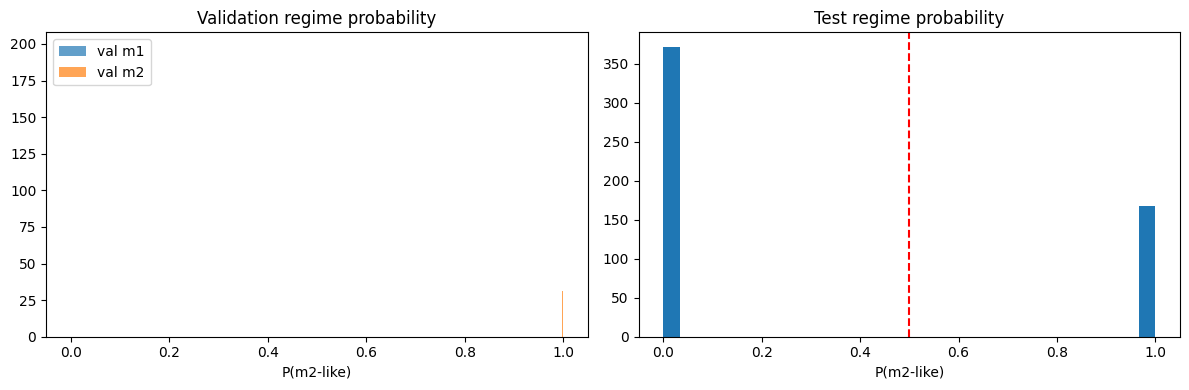

Inferred test block weights: {'m1': np.float64(0.688907), 'm2': np.float64(0.311093)}


In [16]:
def global_features_from_histories(histories,batch=128,desc='global features'):
    out=[]
    for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
        x=np.asarray(histories[start:start+batch],dtype=np.float32)
        out.append(np.concatenate([x.mean(2),x.std(2),(x==0).mean(2)],axis=1).astype(np.float32))
    return np.concatenate(out)

def global_features_for_times(times_by_block,batch=128,desc='train global features'):
    out=[]; labels=[]
    total=sum((len(t)+batch-1)//batch for t in times_by_block)
    with tqdm(total=total,desc=desc,leave=False) as bar:
        for b,(z,times) in enumerate(zip(train_speeds,times_by_block)):
            parts=[]
            for start in range(0,len(times),batch):
                ts=times[start:start+batch]
                w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
                parts.append(np.concatenate([w.mean(2),w.std(2),(w==0).mean(2)],axis=1)); bar.update()
            out.append(np.concatenate(parts)); labels.extend([b]*len(times))
    return np.concatenate(out).astype(np.float32),np.asarray(labels)

global_train,regime_train_y=global_features_for_times(experiment_times)
global_val=global_features_from_histories(val_hist,desc='validation regime features')
global_test=global_features_from_histories(test_hist,desc='test regime features')
global_scaler=StandardScaler().fit(global_train)
regime_clf=LogisticRegression(C=.1,max_iter=1000,random_state=BASE_SEED).fit(global_scaler.transform(global_train),regime_train_y)
val_regime_y=np.r_[np.zeros(VAL_LENGTHS[0],dtype=int),np.ones(VAL_LENGTHS[1],dtype=int)]
val_regime_p=regime_clf.predict_proba(global_scaler.transform(global_val))[:,1]
test_regime_p=regime_clf.predict_proba(global_scaler.transform(global_test))[:,1]
TEST_BLOCK_WEIGHTS=np.array([np.mean(1-test_regime_p),np.mean(test_regime_p)])

regime_report=pd.DataFrame([{
    'val_accuracy':accuracy_score(val_regime_y,val_regime_p>=.5),
    'val_auc':roc_auc_score(val_regime_y,val_regime_p),
    'val_logloss':log_loss(val_regime_y,val_regime_p),
    'test_m1_like':int(np.sum(test_regime_p<.5)),'test_m2_like':int(np.sum(test_regime_p>=.5)),
    'test_m1_weight':TEST_BLOCK_WEIGHTS[0],'test_m2_weight':TEST_BLOCK_WEIGHTS[1]}])
display(regime_report.round(6))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(val_regime_p[:VAL_LENGTHS[0]],bins=20,alpha=.7,label='val m1'); ax[0].hist(val_regime_p[VAL_LENGTHS[0]:],bins=20,alpha=.7,label='val m2'); ax[0].set(title='Validation regime probability',xlabel='P(m2-like)'); ax[0].legend()
ax[1].hist(test_regime_p,bins=30); ax[1].axvline(.5,color='red',ls='--'); ax[1].set(title='Test regime probability',xlabel='P(m2-like)')
plt.tight_layout(); plt.show()
print('Inferred test block weights:',dict(zip(['m1','m2'],TEST_BLOCK_WEIGHTS.round(6))))


## 5. Strong non-neural anchors: AR dan PCA residual

Shared AR memodelkan perubahan dari latest speed dan menjadi anchor konservatif. PCA residual menangkap city-wide low-rank state yang tidak mudah ditangkap per-road AR. Eksperimen manual KNN analog, per-road graph ridge, dan LightGBM residual lebih buruk (38.59, 29.55, dan 30.06), sehingga tidak membebani notebook final.


AR validation:   0%|          | 0/6 [00:00<?, ?it/s]

PCA train block:   0%|          | 0/41 [00:00<?, ?it/s]

PCA train block:   0%|          | 0/17 [00:00<?, ?it/s]

PCA features:   0%|          | 0/12 [00:00<?, ?it/s]

PCA targets:   0%|          | 0/41 [00:00<?, ?it/s]

PCA targets:   0%|          | 0/17 [00:00<?, ?it/s]

PCA ridge horizons:   0%|          | 0/3 [00:00<?, ?it/s]

,model,h5,h10,h15,mean
0,AR,26.44710,30.04726,33.456539,29.983641
1,PCA,26.22452,29.50885,32.513550,29.415640


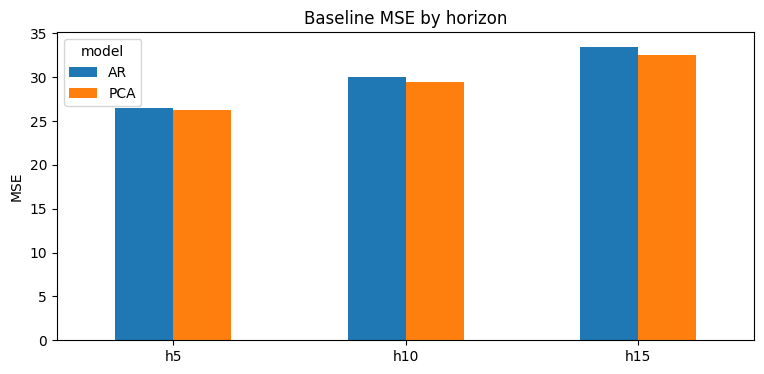

In [17]:
def fit_shared_ar(times_by_block,max_timestamps_per_block=1400,alpha=1000.,seed=BASE_SEED):
    rng=np.random.default_rng(seed); xs=[]; ys={h:[] for h in HORIZONS}
    for z,times in zip(train_speeds,times_by_block):
        take=min(len(times),max_timestamps_per_block if not FAST_MODE else 40)
        chosen=np.sort(rng.choice(times,size=take,replace=False))
        w=np.stack([z[t-HISTORY+1:t+1] for t in chosen]).astype(np.float32)
        xs.append((w-w[:,-1:]).transpose(0,2,1).reshape(-1,HISTORY))
        for h in HORIZONS: ys[h].append((z[chosen+h]-z[chosen]).reshape(-1).astype(np.float32))
    X=np.concatenate(xs); return {h:Ridge(alpha=alpha).fit(X,np.concatenate(ys[h])) for h in HORIZONS}

def predict_ar_histories(models,histories,batch=256,desc=None):
    out=[]; iterator=range(0,len(histories),batch)
    if desc: iterator=tqdm(iterator,desc=desc,leave=False)
    for start in iterator:
        w=np.asarray(histories[start:start+batch],dtype=np.float32)
        x=(w-w[:,-1:]).transpose(0,2,1).reshape(-1,HISTORY); latest=w[:,-1].reshape(-1)
        out.append(np.stack([(latest+models[h].predict(x)).reshape(len(w),N_ROADS) for h in HORIZONS],axis=-1))
    return np.concatenate(out).astype(np.float32)

ar_val_models=fit_shared_ar(experiment_times)
val_pred_ar=predict_ar_histories(ar_val_models,val_hist,desc='AR validation')

def fit_road_pca(row_stops,n_components=PCA_DIM):
    rows=np.concatenate([np.asarray(z[:stop],dtype=np.float32) for z,stop in zip(train_speeds,row_stops)])
    model=PCA(n_components=n_components,whiten=True,svd_solver='randomized',random_state=BASE_SEED).fit(rows)
    del rows; gc.collect(); return model
def summary_from_windows(w):
    return np.stack([w[:,0:3].mean(1),w[:,5:8].mean(1),w[:,10:13].mean(1),w[:,-3:].mean(1),w[:,-1]-w[:,-5]],axis=1)
def pca_features_hist(pca,histories,batch=128,desc='PCA features'):
    out=[]
    for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
        s=summary_from_windows(np.asarray(histories[start:start+batch],dtype=np.float32))
        out.append(np.concatenate([pca.transform(s[:,k]) for k in range(5)],axis=1))
    return np.concatenate(out).astype(np.float32)
def pca_features_times(pca,times_by_block,batch=128):
    out=[]
    for z,times in zip(train_speeds,times_by_block):
        for start in tqdm(range(0,len(times),batch),desc='PCA train block',leave=False):
            ts=times[start:start+batch]; w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
            s=summary_from_windows(w); out.append(np.concatenate([pca.transform(s[:,k]) for k in range(5)],axis=1))
    return np.concatenate(out).astype(np.float32)
def targets_bases(times_by_block,ar_models,batch=128):
    yy=[]; bb=[]
    for z,times in zip(train_speeds,times_by_block):
        for start in tqdm(range(0,len(times),batch),desc='PCA targets',leave=False):
            ts=times[start:start+batch]; w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
            yy.append(np.stack([z[ts+h] for h in HORIZONS],axis=-1)); bb.append(predict_ar_histories(ar_models,w))
    return np.concatenate(yy).astype(np.float32),np.concatenate(bb).astype(np.float32)

pca_val=fit_road_pca(cuts); Fp_train=pca_features_times(pca_val,experiment_times); Fp_val=pca_features_hist(pca_val,val_hist)
Yp,Bp=targets_bases(experiment_times,ar_val_models)
pca_alphas=[1e2,1e4,1e5] if not FAST_MODE else [1e4]
pca_models={}; pca_best_alpha={}; pca_parts=[]
for i,h in enumerate(tqdm(HORIZONS,desc='PCA ridge horizons')):
    best=(float('inf'),None,None,None); residual=Yp[...,i]-Bp[...,i]
    for alpha in pca_alphas:
        m=Ridge(alpha=alpha).fit(Fp_train,residual); pred=val_pred_ar[...,i]+m.predict(Fp_val)
        score=np.mean((val_y[...,i]-pred)**2)
        if score<best[0]: best=(score,alpha,m,pred.astype(np.float32))
    _,pca_best_alpha[h],pca_models[h],pred=best; pca_parts.append(pred)
val_pred_pca=np.stack(pca_parts,axis=-1); del Yp,Bp; gc.collect()
baseline=pd.DataFrame({'model':['AR','PCA'],'h5':[horizon_mse(val_y,val_pred_ar)[0],horizon_mse(val_y,val_pred_pca)[0]],
                       'h10':[horizon_mse(val_y,val_pred_ar)[1],horizon_mse(val_y,val_pred_pca)[1]],
                       'h15':[horizon_mse(val_y,val_pred_ar)[2],horizon_mse(val_y,val_pred_pca)[2]]})
baseline['mean']=baseline[['h5','h10','h15']].mean(1); display(baseline.round(5))
baseline.set_index('model')[['h5','h10','h15']].T.plot(kind='bar',figsize=(9,4),title='Baseline MSE by horizon'); plt.ylabel('MSE'); plt.xticks(rotation=0); plt.show()


## 6. Text preprocessing

Event text semi-terstruktur dan test mengandung kombinasi clause yang tidak selalu pernah terlihat verbatim. Word 1–3 gram TF-IDF dapat berbagi kata event/lokasi, lalu SVD memadatkannya agar road-specific gate tetap ringan.


In [18]:
all_train_text=[s for block in train_texts for s in block]
tfidf=TfidfVectorizer(ngram_range=(1,3),min_df=3,max_features=7000,sublinear_tf=True,dtype=np.float32)
text_sparse=tfidf.fit_transform(all_train_text)
text_dim_actual=min(TEXT_DIM,text_sparse.shape[1]-1)
text_svd=TruncatedSVD(n_components=text_dim_actual,n_iter=7,random_state=BASE_SEED)
all_text_z=text_svd.fit_transform(text_sparse).astype(np.float32)
test_text_z=text_svd.transform(tfidf.transform(test_texts)).astype(np.float32)
offsets=np.cumsum([0]+[len(x) for x in train_texts])
train_text_z=[all_text_z[offsets[i]:offsets[i+1]] for i in range(2)]
print('TF-IDF:',text_sparse.shape,'latent:',all_text_z.shape,'explained variance:',float(text_svd.explained_variance_ratio_.sum()))
del text_sparse,all_text_z; gc.collect()


TF-IDF: (16199, 2021) latent: (16199, 32) explained variance: 0.6661109924316406


0

## 7. Neural family: directed graph + text gate + global FiLM

Semua model memprediksi residual dari mean tiga speed terakhir. FiLM mengubah hidden representation road berdasarkan global trajectory dan regime probability. EMA adalah weight averaging, sedangkan soft-MoE mencampur dua output head menggunakan probabilitas regime. Ablation menjaga komponen lain sama agar kesimpulan kausal lebih masuk akal.


In [19]:
src_np,dst_np=np.nonzero(adjacency!=0); keep=src_np!=dst_np; src_np,dst_np=src_np[keep],dst_np[keep]
out_degree_np=np.bincount(src_np,minlength=N_ROADS).clip(min=1).astype(np.float32)
in_degree_np=np.bincount(dst_np,minlength=N_ROADS).clip(min=1).astype(np.float32)
norm_rows=np.concatenate([np.asarray(z[:cut],dtype=np.float32) for z,cut in zip(train_speeds,cuts)])
road_mean=norm_rows.mean(0).astype(np.float32); road_std=(norm_rows.std(0)+3.).astype(np.float32); del norm_rows; gc.collect()

class TrafficDataset(Dataset):
    def __init__(self,times_by_block): self.index=[(b,int(t)) for b,times in enumerate(times_by_block) for t in times]
    def __len__(self): return len(self.index)
    def __getitem__(self,i):
        b,t=self.index[i]; z=train_speeds[b]
        hist=np.asarray(z[t-HISTORY+1:t+1],dtype=np.float32).T.copy()
        target=np.stack([z[t+h] for h in HORIZONS],axis=-1).astype(np.float32)
        return torch.from_numpy(hist),torch.from_numpy(train_text_z[b][t]),torch.from_numpy(target)

class DirectedGraphBlock(nn.Module):
    def __init__(self,hidden):
        super().__init__(); self.self_linear=nn.Linear(hidden,hidden); self.in_linear=nn.Linear(hidden,hidden,bias=False); self.out_linear=nn.Linear(hidden,hidden,bias=False); self.norm=nn.LayerNorm(hidden); self.dropout=nn.Dropout(.1)
    def forward(self,h,src,dst,in_degree,out_degree):
        incoming=torch.zeros_like(h); outgoing=torch.zeros_like(h)
        incoming.index_add_(1,dst,h[:,src]); outgoing.index_add_(1,src,h[:,dst])
        u=torch.nn.functional.gelu(self.self_linear(h)+self.in_linear(incoming/in_degree[None,:,None])+self.out_linear(outgoing/out_degree[None,:,None]))
        return self.norm(h+self.dropout(u))

@dataclass(frozen=True)
class ModelConfig:
    name:str; use_global:bool=False; use_ema:bool=False; use_moe:bool=False; zero_aux_weight:float=.1

class TrafficNetV3(nn.Module):
    def __init__(self,config,mean_np,std_np,global_scaler_local,regime_clf_local,hidden=HIDDEN_DIM):
        super().__init__(); self.config=config
        self.register_buffer('road_mean',torch.tensor(mean_np).view(1,N_ROADS,1)); self.register_buffer('road_std',torch.tensor(std_np).view(1,N_ROADS,1))
        self.register_buffer('src',torch.tensor(src_np,dtype=torch.long)); self.register_buffer('dst',torch.tensor(dst_np,dtype=torch.long)); self.register_buffer('in_degree',torch.tensor(in_degree_np)); self.register_buffer('out_degree',torch.tensor(out_degree_np))
        self.register_buffer('global_mean',torch.tensor(global_scaler_local.mean_,dtype=torch.float32)); self.register_buffer('global_scale',torch.tensor(global_scaler_local.scale_,dtype=torch.float32))
        raw_coef=regime_clf_local.coef_[0]/global_scaler_local.scale_; raw_intercept=regime_clf_local.intercept_[0]-np.sum(regime_clf_local.coef_[0]*global_scaler_local.mean_/global_scaler_local.scale_)
        self.register_buffer('regime_coef',torch.tensor(raw_coef,dtype=torch.float32)); self.register_buffer('regime_intercept',torch.tensor(raw_intercept,dtype=torch.float32))
        self.road_embedding=nn.Embedding(N_ROADS,12)
        self.history_encoder=nn.Sequential(nn.Linear(HISTORY*3+12,hidden),nn.GELU(),nn.Dropout(.1),nn.Linear(hidden,hidden),nn.GELU())
        gate_dim=16; self.text_context=nn.Sequential(nn.Linear(text_dim_actual,hidden),nn.GELU(),nn.Linear(hidden,hidden)); self.text_query=nn.Linear(text_dim_actual,gate_dim); self.road_event_embedding=nn.Embedding(N_ROADS,gate_dim)
        if config.use_global: self.film=nn.Sequential(nn.Linear(45+1+text_dim_actual,hidden),nn.GELU(),nn.Linear(hidden,hidden*2))
        self.graph_blocks=nn.ModuleList([DirectedGraphBlock(hidden),DirectedGraphBlock(hidden)])
        def make_heads(): return nn.ModuleList([nn.Sequential(nn.Linear(hidden,hidden//2),nn.GELU(),nn.Linear(hidden//2,1)) for _ in HORIZONS])
        self.heads_a=make_heads(); self.heads_b=make_heads() if config.use_moe else None; self.zero_head=nn.Linear(hidden,3)
        for heads in [self.heads_a,self.heads_b]:
            if heads is not None:
                for head in heads: nn.init.zeros_(head[-1].weight); nn.init.zeros_(head[-1].bias)
    def forward(self,hist,text):
        normalized=(hist-self.road_mean)/self.road_std; base=hist[:,:,-3:].mean(-1,keepdim=True); deviations=(hist-base)/self.road_std; zero=(hist==0).to(hist.dtype)
        ids=torch.arange(N_ROADS,device=hist.device); emb=self.road_embedding(ids)[None].expand(len(hist),-1,-1)
        h=self.history_encoder(torch.cat([normalized,deviations,zero,emb],-1))
        context=self.text_context(text)[:,None]; query=self.text_query(text); gate=torch.sigmoid(torch.einsum('bd,rd->br',query,self.road_event_embedding.weight)/(query.shape[-1]**.5)); h=h+gate[...,None]*context
        raw_global=torch.cat([hist.mean(1),hist.std(1,unbiased=False),(hist==0).to(hist.dtype).mean(1)],1)
        regime_p=torch.sigmoid(raw_global@self.regime_coef+self.regime_intercept)
        if self.config.use_global:
            gnorm=(raw_global-self.global_mean)/self.global_scale; gamma,beta=self.film(torch.cat([gnorm,regime_p[:,None],text],1)).chunk(2,1)
            h=h*(1+.15*torch.tanh(gamma[:,None]))+.15*beta[:,None]
        for block in self.graph_blocks: h=block(h,self.src,self.dst,self.in_degree,self.out_degree)
        ra=torch.cat([head(h) for head in self.heads_a],-1)
        if self.heads_b is not None:
            rb=torch.cat([head(h) for head in self.heads_b],-1); residual=(1-regime_p[:,None,None])*ra+regime_p[:,None,None]*rb
        else: residual=ra
        return base+residual*self.road_std,self.zero_head(h),regime_p

ABLATIONS=[ModelConfig('v2_reference'),ModelConfig('global_film',use_global=True),ModelConfig('global_film_ema',use_global=True,use_ema=True),ModelConfig('global_film_ema_soft_moe',use_global=True,use_ema=True,use_moe=True)]
display(pd.DataFrame([asdict(x) for x in ABLATIONS]))


,name,use_global,use_ema,use_moe,zero_aux_weight
0,v2_reference,False,False,False,0.1
1,global_film,True,False,False,0.1
2,global_film_ema,True,True,False,0.1
3,global_film_ema_soft_moe,True,True,True,0.1


## 8. Training, ablation, dan evaluation diagnostics

Epoch, architecture, seed, dan inference loops memakai `tqdm`. Early stopping memilih test-weighted score, tetapi balanced dan block-specific MSE tetap tersimpan sebagai tulisan/CSV. EMA hanya dipakai pada config yang menyatakannya.


Architecture ablations:   0%|          | 0/4 [00:00<?, ?it/s]

v2_reference seed=42:   0%|          | 0/12 [00:00<?, ?it/s]

evaluate v2_reference:   0%|          | 0/89 [00:00<?, ?it/s]

global_film seed=42:   0%|          | 0/12 [00:00<?, ?it/s]

evaluate global_film:   0%|          | 0/89 [00:00<?, ?it/s]

global_film_ema seed=42:   0%|          | 0/12 [00:00<?, ?it/s]

evaluate global_film_ema:   0%|          | 0/89 [00:00<?, ?it/s]

global_film_ema_soft_moe seed=42:   0%|          | 0/12 [00:00<?, ?it/s]

evaluate global_film_ema_soft_moe:   0%|          | 0/89 [00:00<?, ?it/s]

,model,h5,h10,h15,balanced_mean,test_weighted_mean,m1_mean,m2_mean,best_epoch
0,global_film,24.18261,26.926201,29.453131,26.853979,27.78131,29.308451,24.399509,5
1,global_film_ema,23.90554,26.952271,30.071569,26.976460,28.00341,29.694599,24.258310,8
2,global_film_ema_soft_moe,23.89534,26.912880,30.113581,26.973930,28.06087,29.850840,24.097019,8
3,v2_reference,24.98930,28.370621,31.233820,28.197920,28.82585,29.859940,26.535891,8


Selected by inferred test-composition MSE: ModelConfig(name='global_film', use_global=True, use_ema=False, use_moe=False, zero_aux_weight=0.1)


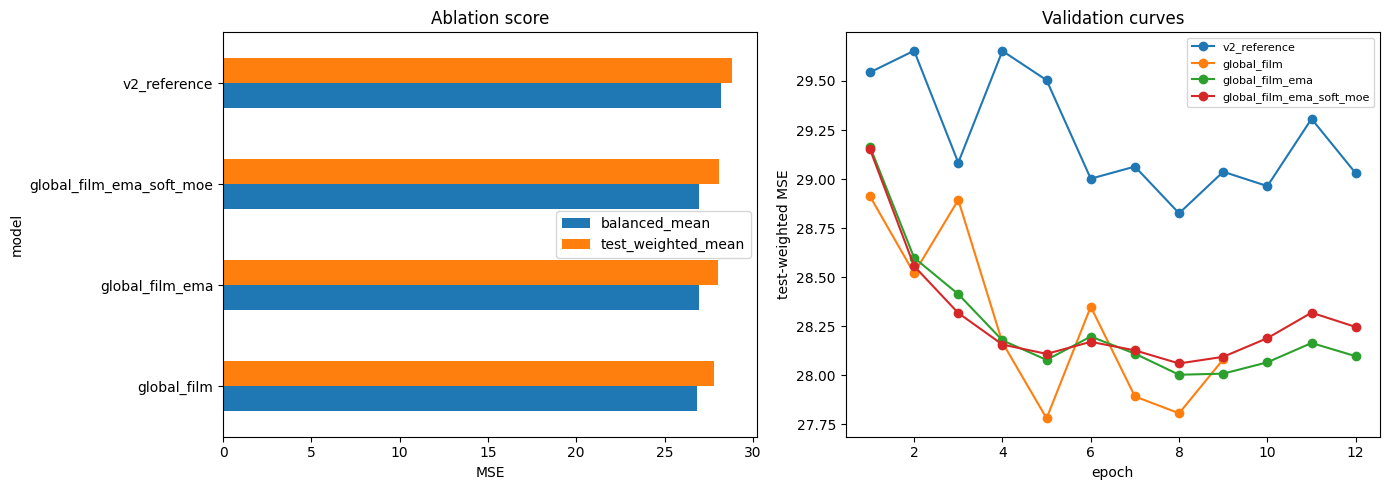

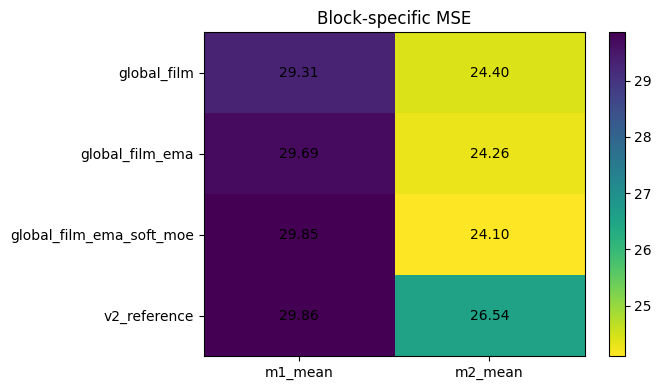

In [20]:
def make_loader(times,shuffle,seed,batch_size=BATCH_SIZE):
    g=torch.Generator(); g.manual_seed(seed)
    return DataLoader(TrafficDataset(times),batch_size=batch_size,shuffle=shuffle,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available(),generator=g)

def evaluate_neural(model,loader,return_pred=False,desc=None):
    model.eval(); parts=[]
    with torch.no_grad():
        iterator=loader if desc is None else tqdm(loader,desc=desc,leave=False)
        for hist,text,target in iterator:
            pred,_,_=model(hist.to(DEVICE),text.to(DEVICE)); parts.append(pred.cpu().numpy())
    pred=np.concatenate(parts); scores=horizon_mse(val_y,pred) if len(pred)==len(val_y) else None
    return (scores,pred) if return_pred else scores

def score_details(y,pred):
    blocks=block_horizon_mse(y,pred); balanced=blocks.mean(0); weighted=TEST_BLOCK_WEIGHTS@blocks
    return blocks,balanced,weighted

@torch.no_grad()
def ema_update(ema_model,model,decay=.995):
    for ep,p in zip(ema_model.parameters(),model.parameters()): ep.mul_(decay).add_(p,alpha=1-decay)
    for eb,b in zip(ema_model.buffers(),model.buffers()): eb.copy_(b)

def train_neural(config,train_times_local,val_times_local,mean_np,std_np,scaler_local,clf_local,seed,epochs):
    set_seed(seed); train_loader=make_loader(train_times_local,True,seed); val_loader=make_loader(val_times_local,False,seed) if val_times_local is not None else None
    model=TrafficNetV3(config,mean_np,std_np,scaler_local,clf_local).to(DEVICE); ema_model=copy.deepcopy(model).eval() if config.use_ema else None
    optimizer=torch.optim.AdamW(model.parameters(),lr=2e-3,weight_decay=1e-4); scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(1,epochs)); pos_weight=torch.tensor(5.,device=DEVICE)
    best_state=None; best=float('inf'); best_epoch=0; stale=0; logs=[]
    bar=trange(1,epochs+1,desc=f'{config.name} seed={seed}',leave=False)
    for epoch in bar:
        model.train(); train_sse=0.; train_n=0; started=time.time()
        for hist,text,target in train_loader:
            hist,text,target=hist.to(DEVICE),text.to(DEVICE),target.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            pred,zero_logits,_=model(hist,text); mse=((pred-target)**2).mean(); loss=mse
            if config.zero_aux_weight: loss=loss+config.zero_aux_weight*torch.nn.functional.binary_cross_entropy_with_logits(zero_logits,(target==0).to(target.dtype),pos_weight=pos_weight)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5.); optimizer.step()
            if ema_model is not None: ema_update(ema_model,model)
            train_sse+=mse.item()*target.numel(); train_n+=target.numel()
        scheduler.step(); chosen=ema_model if ema_model is not None else model; train_mse=train_sse/train_n
        if val_loader is not None:
            _,pred=evaluate_neural(chosen,val_loader,True); blocks,balanced,weighted=score_details(val_y,pred); select=float(weighted.mean())
        else: balanced=weighted=np.repeat(train_mse,3); select=train_mse
        logs.append({'epoch':epoch,'train_mse':train_mse,'balanced_mse':float(np.mean(balanced)),'test_weighted_mse':float(np.mean(weighted)),'seconds':time.time()-started})
        bar.set_postfix(train=f'{train_mse:.3f}',balanced=f'{np.mean(balanced):.3f}',weighted=f'{np.mean(weighted):.3f}')
        if select<best-1e-4:
            best=select; best_epoch=epoch; stale=0; best_state={k:v.detach().cpu().clone() for k,v in chosen.state_dict().items()}
        else:
            stale+=1
            if val_loader is not None and stale>=PATIENCE: break
    model.load_state_dict(best_state); return model,pd.DataFrame(logs),best_epoch,best

val_loader_fixed=make_loader(val_times,False,BASE_SEED)
ablation_rows=[]; ablation_predictions={}; ablation_logs={}; ablation_epochs={}
for config in tqdm(ABLATIONS,desc='Architecture ablations'):
    model,log,best_epoch,best=train_neural(config,experiment_times,val_times,road_mean,road_std,global_scaler,regime_clf,BASE_SEED,EXPERIMENT_EPOCHS)
    _,pred=evaluate_neural(model,val_loader_fixed,True,desc=f'evaluate {config.name}'); blocks,balanced,weighted=score_details(val_y,pred)
    ablation_predictions[config.name]=pred.astype(np.float32); ablation_logs[config.name]=log; ablation_epochs[config.name]=best_epoch
    ablation_rows.append({'model':config.name,'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean(),'m1_mean':blocks[0].mean(),'m2_mean':blocks[1].mean(),'best_epoch':best_epoch})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

ablation_report=pd.DataFrame(ablation_rows).sort_values('test_weighted_mean').reset_index(drop=True); display(ablation_report.round(5))
best_name=ablation_report.iloc[0].model; best_config=next(c for c in ABLATIONS if c.name==best_name)
print('Selected by inferred test-composition MSE:',best_config)

fig,ax=plt.subplots(1,2,figsize=(14,5))
ablation_report.sort_values('test_weighted_mean').plot.barh(x='model',y=['balanced_mean','test_weighted_mean'],ax=ax[0]); ax[0].set(title='Ablation score',xlabel='MSE')
for name,log in ablation_logs.items(): ax[1].plot(log.epoch,log.test_weighted_mse,marker='o',label=name)
ax[1].set(title='Validation curves',xlabel='epoch',ylabel='test-weighted MSE'); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

heat=ablation_report.set_index('model')[['m1_mean','m2_mean']]
fig,ax=plt.subplots(figsize=(7,4)); im=ax.imshow(heat.values,aspect='auto',cmap='viridis_r'); ax.set_xticks(range(2),heat.columns); ax.set_yticks(range(len(heat)),heat.index)
for i in range(len(heat)):
    for j in range(2): ax.text(j,i,f'{heat.iloc[i,j]:.2f}',ha='center',va='center')
ax.set_title('Block-specific MSE'); plt.colorbar(im,ax=ax); plt.tight_layout(); plt.show()


## 9. Stride-1 multi-seed confirmation

Architecture search memakai stride 2 untuk efisiensi. Kandidat terbaik kemudian diuji ulang pada stride 1 dan tiga seed. Kita memilih median best epoch untuk full refit; seed averaging mengurangi variance tanpa mengintip test target.


Stride-1 seed confirmation:   0%|          | 0/3 [00:00<?, ?it/s]

global_film seed=42:   0%|          | 0/16 [00:00<?, ?it/s]

seed 42 validation:   0%|          | 0/89 [00:00<?, ?it/s]

global_film seed=2026:   0%|          | 0/16 [00:00<?, ?it/s]

seed 2026 validation:   0%|          | 0/89 [00:00<?, ?it/s]

global_film seed=3407:   0%|          | 0/16 [00:00<?, ?it/s]

seed 3407 validation:   0%|          | 0/89 [00:00<?, ?it/s]

,seed,h5,h10,h15,balanced_mean,test_weighted_mean,best_epoch
0,42,23.853350,26.795080,29.69389,26.780781,27.83254,10
1,2026,23.931709,26.791439,29.43750,26.720221,27.65533,6
2,3407,24.065950,26.903259,29.69832,26.889179,27.82804,3


Seed-average balanced: [23.65148 26.36599 28.9547 ] mean 26.324057
Seed-average test-weighted: [24.79292 27.35993 29.82565] mean 27.326165004388898 | refit epochs: 6


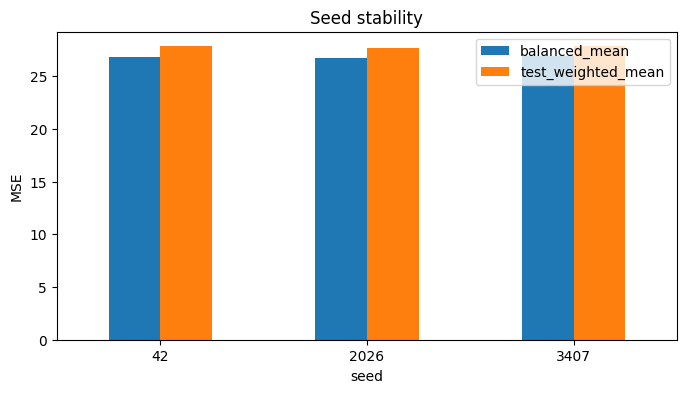

In [21]:
seed_predictions=[]; seed_rows=[]; seed_epochs=[]
for seed in tqdm(SEEDS,desc='Stride-1 seed confirmation'):
    model,log,best_epoch,best=train_neural(best_config,final_train_times,val_times,road_mean,road_std,global_scaler,regime_clf,seed,SEED_SEARCH_EPOCHS)
    _,pred=evaluate_neural(model,val_loader_fixed,True,desc=f'seed {seed} validation'); blocks,balanced,weighted=score_details(val_y,pred)
    seed_predictions.append(pred.astype(np.float32)); seed_epochs.append(best_epoch)
    seed_rows.append({'seed':seed,'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean(),'best_epoch':best_epoch})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
seed_report=pd.DataFrame(seed_rows); display(seed_report.round(5))
val_pred_gnn=np.mean(seed_predictions,axis=0).astype(np.float32); gnn_blocks,gnn_balanced,gnn_weighted=score_details(val_y,val_pred_gnn)
refit_epochs=max(1,int(np.median(seed_epochs)))
print('Seed-average balanced:',gnn_balanced.round(5),'mean',gnn_balanced.mean())
print('Seed-average test-weighted:',gnn_weighted.round(5),'mean',gnn_weighted.mean(),'| refit epochs:',refit_epochs)
seed_report.set_index('seed')[['balanced_mean','test_weighted_mean']].plot(kind='bar',figsize=(8,4),title='Seed stability'); plt.ylabel('MSE'); plt.xticks(rotation=0); plt.show()


## 10. Test-weighted non-negative ensemble

AR, PCA, dan neural memiliki error pattern berbeda. Bobot simplex non-negatif dipelajari per horizon dengan sample weights 69/31 hasil regime inference. Constraint mencegah extrapolative weight yang berbahaya untuk MSE. Balanced score tetap dihitung sebagai audit.


,horizon,w_AR,w_PCA,w_GNN,balanced_MSE,test_weighted_MSE
0,h5,0.0,0.088630,0.911370,23.635349,24.768147
1,h10,0.0,0.185073,0.814927,26.274779,27.206586
2,h15,0.0,0.259443,0.740557,28.745426,29.423386


V3 balanced mean: 26.21851921081543 | V2 balanced reference: 27.426926
V3 inferred-test-weighted mean: 27.132707124618218


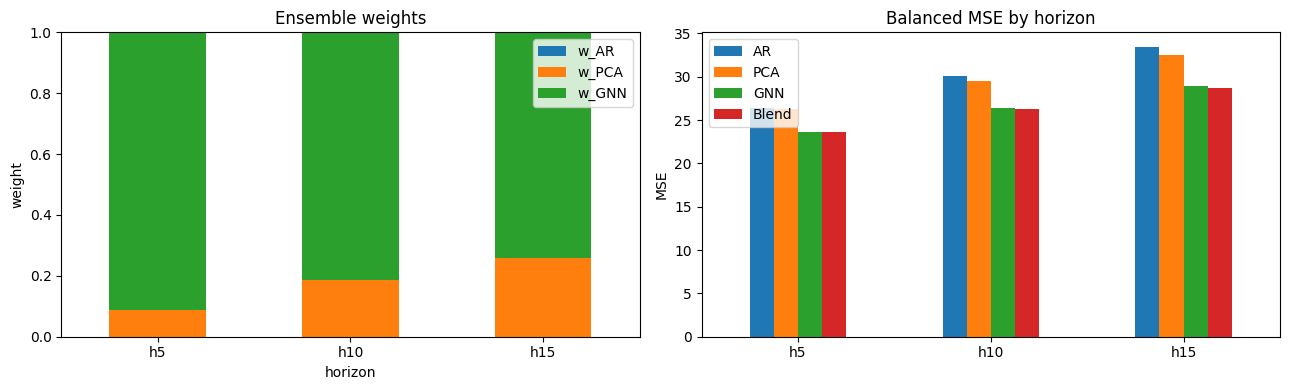

In [22]:
model_names=['AR','PCA','GNN']; val_candidates=[val_pred_ar,val_pred_pca,val_pred_gnn]
def simplex_weights_weighted(y,preds):
    X=np.stack([p.reshape(-1).astype(np.float64) for p in preds],1); yy=y.reshape(-1).astype(np.float64)
    sample_w=np.r_[np.repeat(TEST_BLOCK_WEIGHTS[0]/VAL_LENGTHS[0],VAL_LENGTHS[0]),np.repeat(TEST_BLOCK_WEIGHTS[1]/VAL_LENGTHS[1],VAL_LENGTHS[1])]
    w=np.repeat(sample_w,N_ROADS); w=w/w.sum(); G=X.T@(X*w[:,None]); c=X.T@(yy*w)
    fun=lambda a:float(a@G@a-2*c@a); jac=lambda a:2*G@a-2*c
    result=minimize(fun,np.full(len(preds),1/len(preds)),jac=jac,bounds=[(0,1)]*len(preds),constraints={'type':'eq','fun':lambda a:a.sum()-1},method='SLSQP',options={'ftol':1e-12,'maxiter':200})
    assert result.success,result.message; return result.x

blend_weights=[]; blend_parts=[]; blend_rows=[]
for i,h in enumerate(HORIZONS):
    w=simplex_weights_weighted(val_y[...,i],[p[...,i] for p in val_candidates]); pred=sum(w[j]*val_candidates[j][...,i] for j in range(3))
    blend_weights.append(w); blend_parts.append(pred.astype(np.float32)); cut=VAL_LENGTHS[0]
    blocks=np.array([np.mean((val_y[:cut,:,i]-pred[:cut])**2),np.mean((val_y[cut:cut+VAL_LENGTHS[1],:,i]-pred[cut:cut+VAL_LENGTHS[1]])**2)])
    blend_rows.append({'horizon':f'h{h}',**{f'w_{n}':w[j] for j,n in enumerate(model_names)},'balanced_MSE':blocks.mean(),'test_weighted_MSE':TEST_BLOCK_WEIGHTS@blocks})
val_pred_blend=np.stack(blend_parts,-1); blend_report=pd.DataFrame(blend_rows); display(blend_report.round(6))
blend_blocks,blend_balanced,blend_weighted=score_details(val_y,val_pred_blend)
print('V3 balanced mean:',float(blend_balanced.mean()),'| V2 balanced reference:',V2_REFERENCE_MSE)
print('V3 inferred-test-weighted mean:',float(blend_weighted.mean()))

fig,ax=plt.subplots(1,2,figsize=(13,4))
blend_report.set_index('horizon')[[f'w_{n}' for n in model_names]].plot(kind='bar',stacked=True,ax=ax[0],ylim=(0,1),title='Ensemble weights'); ax[0].set_ylabel('weight'); ax[0].tick_params(axis='x',rotation=0)
comparison=pd.DataFrame({'AR':horizon_mse(val_y,val_pred_ar),'PCA':horizon_mse(val_y,val_pred_pca),'GNN':gnn_balanced,'Blend':blend_balanced},index=[f'h{h}' for h in HORIZONS])
comparison.plot(kind='bar',ax=ax[1],title='Balanced MSE by horizon'); ax[1].set_ylabel('MSE'); ax[1].tick_params(axis='x',rotation=0); plt.tight_layout(); plt.show()

experiment_results=pd.concat([baseline.rename(columns={'mean':'balanced_mean'}),ablation_report.drop(columns=['best_epoch']),pd.DataFrame([{'model':'GNN_seed_average','h5':gnn_balanced[0],'h10':gnn_balanced[1],'h15':gnn_balanced[2],'balanced_mean':gnn_balanced.mean(),'test_weighted_mean':gnn_weighted.mean()}]),pd.DataFrame([{'model':'V3_blend','h5':blend_balanced[0],'h10':blend_balanced[1],'h15':blend_balanced[2],'balanced_mean':blend_balanced.mean(),'test_weighted_mean':blend_weighted.mean()}])],ignore_index=True,sort=False)
experiment_results.to_csv(OUTPUT_DIR/'v3_experiment_results.csv',index=False)


## 11. Full-data refit dan test inference

Setelah seluruh keputusan dikunci oleh validation, AR/PCA/global normalization/regime context difit ulang pada semua train. Neural dilatih ulang dari nol untuk setiap seed selama median best epoch. Tidak ada test target yang dipakai.


In [23]:
full_times=[valid_times(len(z),HISTORY-1,len(z),FINAL_STRIDE) for z in train_speeds]
if FAST_MODE: full_times=[t[-min(110,len(t)):] for t in full_times]
ar_full=fit_shared_ar(full_times,max_timestamps_per_block=1800); test_pred_ar=predict_ar_histories(ar_full,test_hist,desc='Full AR test')
pca_full=fit_road_pca([len(z) for z in train_speeds]); F_full=pca_features_times(pca_full,full_times); F_test=pca_features_hist(pca_full,test_hist,desc='PCA test')
Y_full,B_full=targets_bases(full_times,ar_full); test_pca_parts=[]
for i,h in enumerate(tqdm(HORIZONS,desc='Full PCA ridge')):
    m=Ridge(alpha=pca_best_alpha[h]).fit(F_full,Y_full[...,i]-B_full[...,i]); test_pca_parts.append(test_pred_ar[...,i]+m.predict(F_test))
test_pred_pca=np.stack(test_pca_parts,-1).astype(np.float32); del F_full,Y_full,B_full; gc.collect()

full_global,full_regime_y=global_features_for_times(full_times,desc='Full global context')
full_scaler=StandardScaler().fit(full_global); full_regime_clf=LogisticRegression(C=.1,max_iter=1000,random_state=BASE_SEED).fit(full_scaler.transform(full_global),full_regime_y)
all_rows=np.concatenate([np.asarray(z,dtype=np.float32) for z in train_speeds]); full_mean=all_rows.mean(0).astype(np.float32); full_std=(all_rows.std(0)+3.).astype(np.float32); del all_rows,full_global; gc.collect()

class TestDataset(Dataset):
    def __len__(self): return len(test_hist)
    def __getitem__(self,i): return torch.from_numpy(np.asarray(test_hist[i],dtype=np.float32).T.copy()),torch.from_numpy(test_text_z[i])
test_loader=DataLoader(TestDataset(),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available())
test_seed_predictions=[]
for seed in tqdm(SEEDS,desc='Full neural refits'):
    model,log,_,_=train_neural(best_config,full_times,None,full_mean,full_std,full_scaler,full_regime_clf,seed,refit_epochs)
    model.eval(); parts=[]
    with torch.no_grad():
        for hist,text in tqdm(test_loader,desc=f'test inference seed {seed}',leave=False):
            pred,_,_=model(hist.to(DEVICE),text.to(DEVICE)); parts.append(pred.cpu().numpy())
    test_seed_predictions.append(np.concatenate(parts).astype(np.float32))
    torch.save({'config':asdict(best_config),'seed':seed,'epochs':refit_epochs,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()}},OUTPUT_DIR/f'v3_{best_config.name}_seed{seed}.pt')
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
test_pred_gnn=np.mean(test_seed_predictions,0).astype(np.float32); W=np.asarray(blend_weights,dtype=np.float32); test_pred=np.empty_like(test_pred_ar)
for i in range(3): test_pred[...,i]=W[i,0]*test_pred_ar[...,i]+W[i,1]*test_pred_pca[...,i]+W[i,2]*test_pred_gnn[...,i]
test_pred=np.clip(test_pred,0,160).astype(np.float32)
print('Test prediction:',test_pred.shape,'range',float(test_pred.min()),float(test_pred.max()),'mean',float(test_pred.mean()))


Full AR test:   0%|          | 0/3 [00:00<?, ?it/s]

PCA train block:   0%|          | 0/87 [00:00<?, ?it/s]

PCA train block:   0%|          | 0/40 [00:00<?, ?it/s]

PCA test:   0%|          | 0/5 [00:00<?, ?it/s]

PCA targets:   0%|          | 0/87 [00:00<?, ?it/s]

PCA targets:   0%|          | 0/40 [00:00<?, ?it/s]

... (6 outputs left out)

test inference seed 2026:   0%|          | 0/34 [00:00<?, ?it/s]

global_film seed=3407:   0%|          | 0/6 [00:00<?, ?it/s]

test inference seed 3407:   0%|          | 0/34 [00:00<?, ?it/s]

Test prediction: (540, 1260, 3) range 0.0 99.50518035888672 mean 52.938743591308594


## 12. Submission audit dan visualisasi hasil

Urutan reshape mengikuti sample → horizon → road persis seperti sample submission. Audit memeriksa ID boundary, NaN, range, distribusi horizon, besar koreksi dari mean-last-3, dan horizon separation.


,horizon,mean,std,min,max,zeros,mean_abs_vs_mean3
0,h5,52.913792,19.522739,0.0,99.505180,14316,1.96145
1,h10,52.945419,19.426590,0.0,98.892242,22689,2.26494
2,h15,52.956959,19.375851,0.0,99.324112,17563,2.43377


Mean absolute h5-h10 / h10-h15: 0.4654971659183502 0.318855345249176


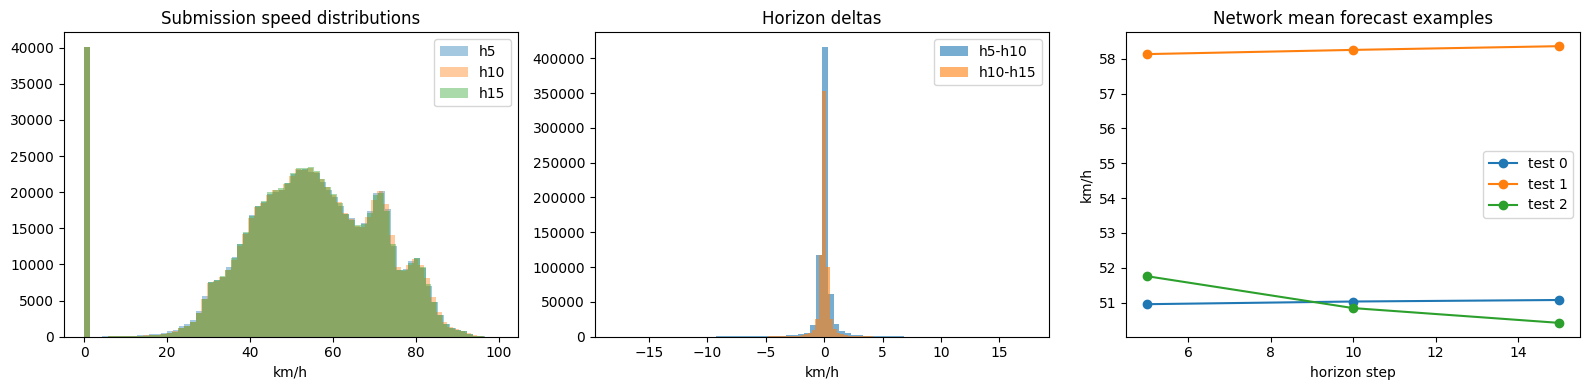

Saved: /kaggle/working/submission_v3.csv
Also saved: v3_experiment_results.csv, v3_diagnostics.json, and seed checkpoints


,id,speed
0,test_00000_h5_r0,49.541504
1,test_00000_h5_r1,69.157562
2,test_00000_h5_r2,68.731560
2041197,test_00539_h15_r1257,64.713745
2041198,test_00539_h15_r1258,69.456757
2041199,test_00539_h15_r1259,0.000000


In [24]:
submission=sample_submission.copy(); flat=test_pred.transpose(0,2,1).reshape(-1)
assert len(flat)==len(submission); assert submission.id.iloc[0]=='test_00000_h5_r0'; assert submission.id.iloc[N_ROADS]=='test_00000_h10_r0'; assert submission.id.iloc[3*N_ROADS]=='test_00001_h5_r0'; assert submission.id.iloc[-1]=='test_00539_h15_r1259'
submission['speed']=flat; assert submission.speed.notna().all() and submission.speed.between(0,160).all()
submission_path=OUTPUT_DIR/'submission_v3.csv'; submission.to_csv(submission_path,index=False)

mean3=test_hist[:,-3:].mean(1); audit=[]
for i,h in enumerate(HORIZONS):
    x=test_pred[...,i]; audit.append({'horizon':f'h{h}','mean':x.mean(),'std':x.std(),'min':x.min(),'max':x.max(),'zeros':int(np.sum(x==0)),'mean_abs_vs_mean3':np.mean(np.abs(x-mean3))})
audit_df=pd.DataFrame(audit); display(audit_df.round(5)); print('Mean absolute h5-h10 / h10-h15:',float(np.mean(np.abs(test_pred[...,0]-test_pred[...,1]))),float(np.mean(np.abs(test_pred[...,1]-test_pred[...,2]))))

fig,ax=plt.subplots(1,3,figsize=(16,4))
for i,h in enumerate(HORIZONS): ax[0].hist(test_pred[...,i].ravel(),bins=70,alpha=.4,label=f'h{h}')
ax[0].set(title='Submission speed distributions',xlabel='km/h'); ax[0].legend()
ax[1].hist((test_pred[...,0]-test_pred[...,1]).ravel(),bins=70,alpha=.6,label='h5-h10'); ax[1].hist((test_pred[...,1]-test_pred[...,2]).ravel(),bins=70,alpha=.6,label='h10-h15'); ax[1].set(title='Horizon deltas',xlabel='km/h'); ax[1].legend()
sample_ids=[0,min(1,len(test_pred)-1),min(2,len(test_pred)-1)]
for s in sample_ids: ax[2].plot(HORIZONS,test_pred[s].mean(0),marker='o',label=f'test {s}')
ax[2].set(title='Network mean forecast examples',xlabel='horizon step',ylabel='km/h'); ax[2].legend(); plt.tight_layout(); plt.show()

diagnostics={'selected_config':asdict(best_config),'refit_epochs':refit_epochs,'test_block_weights':TEST_BLOCK_WEIGHTS.tolist(),'balanced_validation_mse':float(blend_balanced.mean()),'test_weighted_validation_mse':float(blend_weighted.mean()),'ensemble_weights':W.tolist(),'submission_rows':len(submission)}
(OUTPUT_DIR/'v3_diagnostics.json').write_text(json.dumps(diagnostics,indent=2))
print('Saved:',submission_path); print('Also saved: v3_experiment_results.csv, v3_diagnostics.json, and seed checkpoints')
display(pd.concat([submission.head(3),submission.tail(3)]))


## 13. Cara membaca hasil dan keputusan berikutnya

1. Pastikan semua cell selesai tanpa traceback dan `submission_v3.csv` berisi 2.041.200 row.
2. Lihat `test_weighted_mean` untuk memilih architecture; lihat `balanced_mean` untuk membandingkan secara kasar dengan V2 27.4269. Karena V3 memperketat boundary train, selisih kecil jangan di-overinterpretasi.
3. Global FiLM dianggap berguna hanya jika membaik pada test-weighted score tanpa collapse besar di salah satu block.
4. Soft-MoE dipakai hanya bila mengalahkan FiLM biasa. Model lebih rumit bukan otomatis lebih baik.
5. Bandingkan leaderboard V1, V2, dan V3 sebagai submission terpisah. Jika local V3 naik tetapi leaderboard turun, next step terbaik adalah rolling multi-fold validation dan blend lintas versi, bukan menambah epoch buta.

Output untuk dibawa pulang dari Kaggle:

- `/kaggle/working/submission_v3.csv`
- `/kaggle/working/v3_experiment_results.csv`
- `/kaggle/working/v3_diagnostics.json`
- `/kaggle/working/v3_<selected_config>_seed*.pt`
- executed notebook ini
